# Heat, drought and heavy precipitation — trends and drivers of yield losses

Which weather extreme is behind a region's bad wheat years, and is it becoming
more frequent? Three yield series are analysed side by side on the CyBench
units:

| Series | Source | Years |
|---|---|---|
| Observed | CyBench, × (1 − 0.135) to dry matter | 1980–2021 (~390 units before 1998, ~700 after) |
| SIMPLACE | Calibrated MSWX production run, unit means | 1980–2024 |
| torchcrop | Calibrated MSWX production run, unit means | 2000–2024 |

**Hazards** are season indices computed from the same daily MSWX files the
models ran on (`extremes.py`), in windows anchored on each cell's
climatological phenology:

* **Heat**: days ≥ 31 °C around flowering, degree days above 30 °C in grain
  fill, and TX90p in grain fill (days above the cell's own 90th percentile, so
  a northern heat wave counts even when it never reaches 30 °C).
* **Drought**: precipitation before anthesis and during grain fill, and the
  longest dry spell from stem elongation to maturity. The drought indices are
  **precipitation-only on purpose**. Reference ET rises with temperature, so a
  P − ET₀ drought index would credit heat damage to drought. The water balance
  (Hargreaves ET₀) appears only in the trend maps of §2.
* **Heavy precipitation**: the wettest 5 days (Rx5day) of the season, and R95p
  (rain on days above the cell's wet-day 95th percentile) over the season and
  during grain fill.
* **Other weather**: a control group with season mean temperature, grain-fill
  radiation and winter frost days. It stops the hazard groups from being
  credited with an anomaly that a merely warm or dull season explains.

**Yield losses** are seasons ≥ 10 % below the unit's own linear trend. Each series
is detrended separately, so the observed technology trend is removed and the
models' climate and CO₂ trend is removed as well.

**Attribution** (`attribution.py`): gradient boosting of the detrended anomaly
on each index's departure from the unit's 1980–2024 climatology, cross-validated
with whole years held out. That baseline is fixed and shared, so one season
carries **identical hazard anomalies** in all three series. The yield trend is
not shared: each series is detrended separately, because only the observed one
carries breeding and management gains. Importance is the loss of held-out R² when one hazard's
indices are permuted together. A season's contribution from a hazard is how much
of the predicted anomaly disappears when that hazard is set to normal. A
unit's **driver** is the hazard with the most negative mean contribution over
its loss years.

## 0. Setup

In [1]:
import logging
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import attribution as att
import extremes as ex

from cropmodelling4eu.evaluation import production as prod
from cropmodelling4eu.evaluation.fullrun import load_runs
from cropmodelling4eu.evaluation.plots import EUROPE_PROJECTION, country_choropleth, save
from cropmodelling4eu.evaluation.regions import load_admin_polygons
from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, use_style

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s",
                    force=True)
PALETTE = use_style("light")

RUN = prod.PRODUCTION_RUN_DIR
CALIBRATION = prod.CALIBRATION_DIR
prod.check_year_matched(RUN)

YEARS = (1980, 2024)
OUT = Path(os.environ.get("EXTREMES_ANALYSIS_DIR", RUN / "analysis" / "extremes"))
FIGURES, TABLES = OUT / "figures", OUT / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

COLOURS = {"observed": PALETTE["primary"], "simplace": PALETTE["series_1"],
           "torchcrop": PALETTE["series_2"]}
GROUP_COLOURS = {"heat": att.DRIVERS["heat"], "drought": att.DRIVERS["drought"],
                 "wet": att.DRIVERS["heavy precipitation"], "other": att.DRIVERS["other weather"],
                 "descriptive": PALETTE["series_3"]}


def _limit(values: pd.Series, q: float = 0.95) -> float:
    finite = values.replace([np.inf, -np.inf], np.nan).dropna()
    return float(finite.abs().quantile(q)) if len(finite) else 1.0


def map_row(n: int, height: float = 5.0):
    return plt.subplots(1, n, figsize=(4.4 * n, height),
                        subplot_kw={"projection": EUROPE_PROJECTION})

print(f"run     : {RUN}")
print(f"outputs : {OUT}")

run     : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx
outputs : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx/analysis/extremes


## 1. Inputs

In [2]:
runs = load_runs(RUN / "simplace" / "simplace_europe.parquet",
                 RUN / "torchcrop" / "torchcrop_europe.parquet", years=YEARS)
cell_to_adm = pd.read_parquet(CALIBRATION / "cell_to_adm.parquet")
countries = sorted(cell_to_adm["adm_country"].dropna().unique())
reference = prod.load_reference(countries, YEARS)
polygons = load_admin_polygons(countries)
units = cell_to_adm.dropna(subset=["adm_id"]).drop_duplicates("adm_id")
unit_country = pd.Series(units["adm_country"].to_numpy(), index=units["adm_id"].astype("string"))

windows, cell_extremes = ex.load_or_compute(
    OUT / "season_extremes.parquet", RUN / "torchcrop" / "torchcrop_europe.parquet", YEARS)
features = att.unit_extremes(cell_extremes, cell_to_adm)
anomalies = att.detrend(att.unit_yields(runs, reference, cell_to_adm))
anomalies.to_csv(TABLES / "unit_yield_anomalies.csv", index=False)

pd.DataFrame({ds: {
    "units": g["adm_id"].nunique(),
    "seasons": len(g),
    "years": f"{g['year'].min()}-{g['year'].max()}",
    "loss seasons (%)": round(100 * g["loss"].mean(), 1),
    "anomaly sd (%)": round(g.groupby("adm_id")["anomaly_pct"].std().median(), 1),
} for ds, g in anomalies.groupby("dataset")}).T.loc[list(att.DATASETS)]

WARNING cropmodelling4eu.evaluation.torchcrop: 183 of 1711524 rows (0.01%) never reached maturity; their dates are NaN
WARNING cropmodelling4eu.evaluation.fullrun: simplace: 32646 of 3087736 rows (1.06%) carry a season shorter than 150 days -- the (0, 365] wrap in collect.to_run_schema, not a 5-day crop. Their durations are dropped; their dates are kept


,units,seasons,years,loss seasons (%),anomaly sd (%)
observed,811,23969,1980-2021,18.6,10.9
simplace,849,38202,1980-2024,19.2,12.4
torchcrop,849,21217,2000-2024,12.6,7.0


The index definitions. Each cell's windows come from its median sowing date,
days to anthesis and days to maturity in the torchcrop run, and the same
windows are used in every year:

In [3]:
display(pd.DataFrame(ex.FEATURES, index=["group", "unit", "definition"]).T)  # "descriptive" = trends only
windows[["sowing_doy", "days_to_anthesis", "days_to_maturity"]].describe().round(0).T

,group,unit,definition
heat_days_flowering,heat,days,"Days Tmax ≥ 31 °C, flowering"
edd_grainfill,heat,°C·d,"Degree days > 30 °C, grain fill"
tx90p_grainfill,heat,days,"Days Tmax > cell's 90th percentile (TX90p), gr..."
prec_preanthesis,drought,mm,"Precipitation, pre-anthesis"
prec_grainfill,drought,mm,"Precipitation, grain fill"
cdd_spring,drought,days,"Longest dry spell, pre-anthesis → maturity"
rx5day_season,wet,mm,Wettest 5 days of the season
r95p_season,wet,mm,"Rain on very wet days (R95p), season"
r95p_grainfill,wet,mm,"Rain on very wet days (R95p), grain fill"
tmean_season,other,°C,"Mean temperature, season"


,count,mean,std,min,25%,50%,75%,max
sowing_doy,68685.0,257.0,22.0,215.0,239.0,247.0,274.0,333.0
days_to_anthesis,68685.0,261.0,34.0,148.0,243.0,269.0,285.0,326.0
days_to_maturity,68685.0,308.0,35.0,182.0,296.0,314.0,333.0,375.0


## 2. Trends in the extremes, 1980–2024

Theil–Sen slope per decade of each unit's mean index, with a Mann–Kendall test.
The top row shows the 1980–2024 climatology. In the bottom row only units with
**p < 0.05** are coloured.

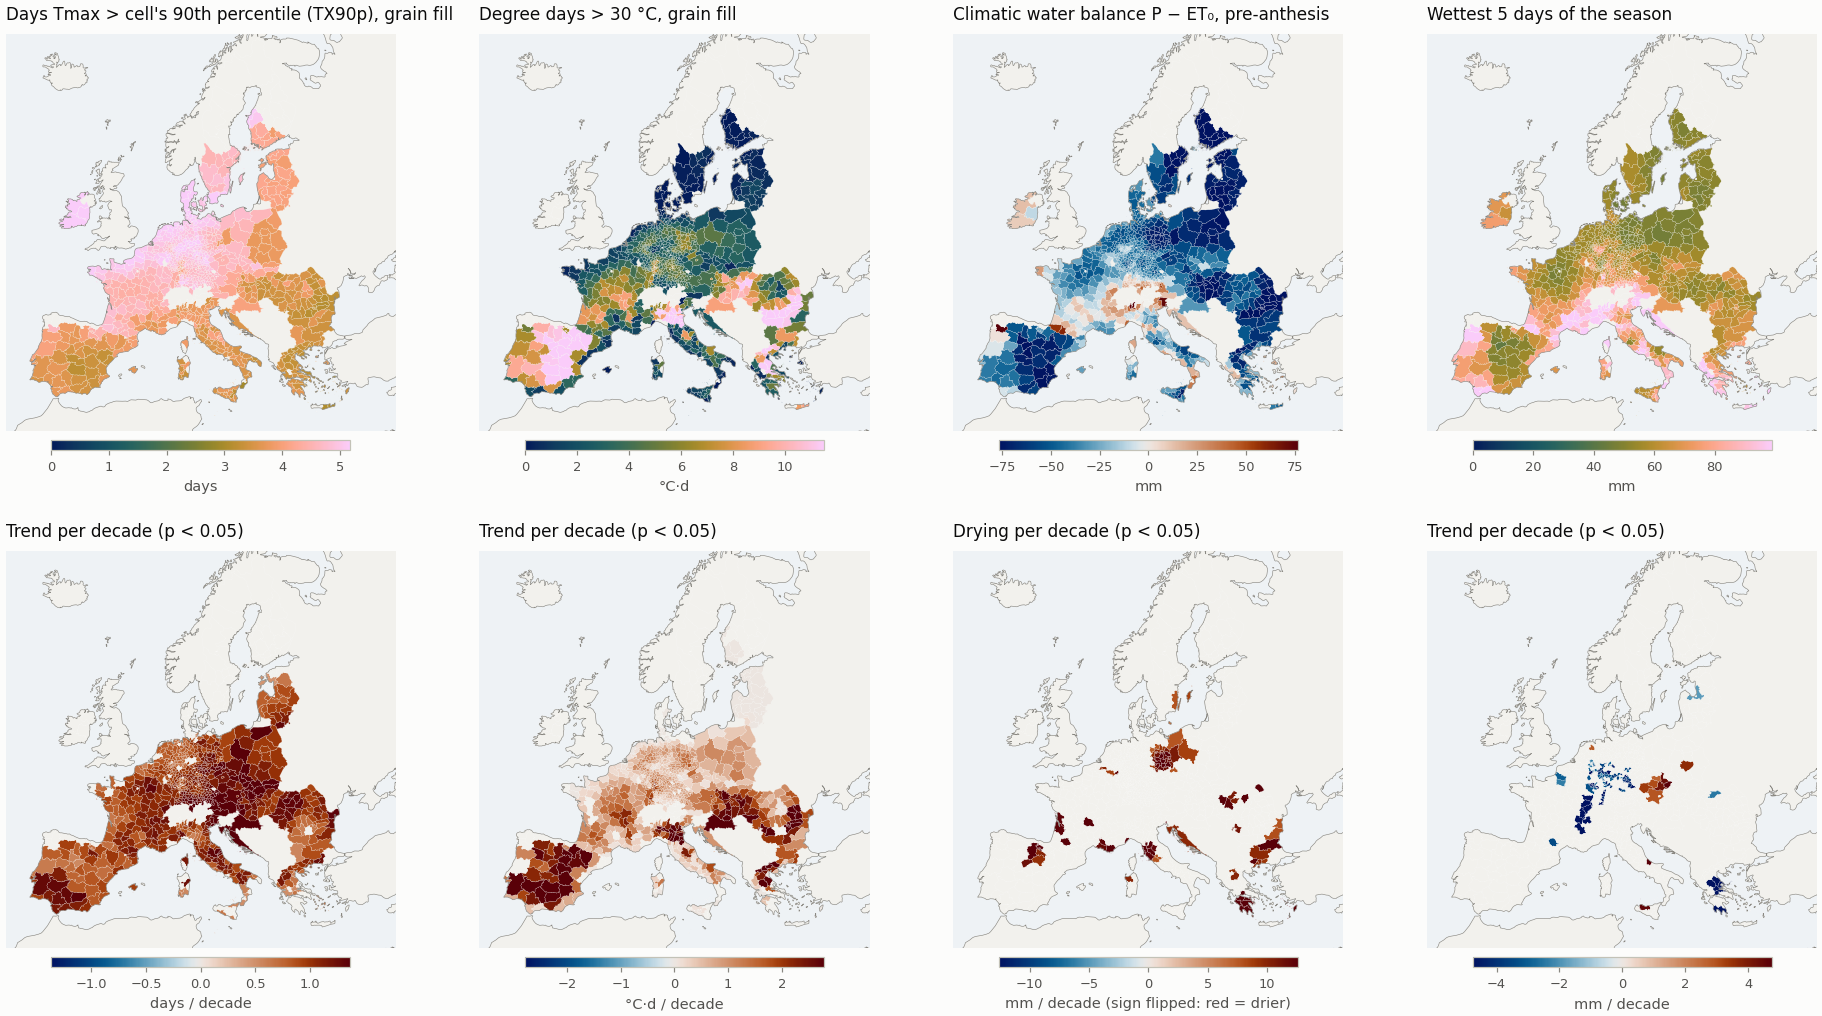

In [4]:
hazard_trends = att.sen_trends(features, list(ex.FEATURES))
hazard_trends.to_csv(TABLES / "hazard_trends.csv", index=False)
HEADLINE = ["tx90p_grainfill", "edd_grainfill", "cwb_preanthesis", "rx5day_season"]

fig, axes = plt.subplots(2, len(HEADLINE), figsize=(4.4 * len(HEADLINE), 9.6),
                         subplot_kw={"projection": EUROPE_PROJECTION})
for c, var in enumerate(HEADLINE):
    group, unit, label = ex.FEATURES[var]
    t = hazard_trends[hazard_trends["variable"] == var].set_index("adm_id")
    reverse = var.startswith("cwb")
    country_choropleth(polygons, t["mean"], key_col="adm_id", diverging=reverse,
                       cmap=None if reverse else SEQUENTIAL_CMAP,
                       vmin=0.0, vmax=_limit(t["mean"]),
                       linewidth=0.1, title=label, cbar_label=unit, ax=axes[0, c])
    sig = t["slope"].where(t["p"] < 0.05)
    country_choropleth(polygons, -sig if reverse else sig, key_col="adm_id", diverging=True,
                       vmax=_limit(t["slope"]), linewidth=0.1,
                       title=("Drying" if reverse else "Trend") + " per decade (p < 0.05)",
                       cbar_label=f"{unit} / decade" + (" (sign flipped: red = drier)" if reverse else ""),
                       ax=axes[1, c])
fig.tight_layout()
save(fig, "hazard_trends_maps", FIGURES);

The share of units where each index rises or falls significantly. For the water
balance a fall means drier conditions:

In [5]:
summary = (hazard_trends.assign(
    up=(hazard_trends["p"] < 0.05) & (hazard_trends["slope"] > 0),
    down=(hazard_trends["p"] < 0.05) & (hazard_trends["slope"] < 0))
    .groupby("variable")
    .agg(units=("slope", "size"), median_slope_per_decade=("slope", "median"),
         significant_up_pct=("up", "mean"), significant_down_pct=("down", "mean")))
summary[["significant_up_pct", "significant_down_pct"]] *= 100
summary.insert(0, "group", summary.index.map(lambda v: ex.FEATURES[v][0]))
summary.loc[list(ex.FEATURES)].round(2)

,group,units,median_slope_per_decade,significant_up_pct,significant_down_pct
variable,,,,,
heat_days_flowering,heat,630,0.00,0.00,0.00
edd_grainfill,heat,840,0.69,85.71,0.00
tx90p_grainfill,heat,849,1.00,88.34,0.00
prec_preanthesis,drought,849,-0.95,0.47,3.89
prec_grainfill,drought,849,-0.64,2.12,0.71
cdd_spring,drought,849,0.19,6.12,0.24
rx5day_season,wet,849,-0.88,1.30,11.90
r95p_season,wet,849,-2.25,3.77,12.84
r95p_grainfill,wet,847,0.00,2.24,2.72


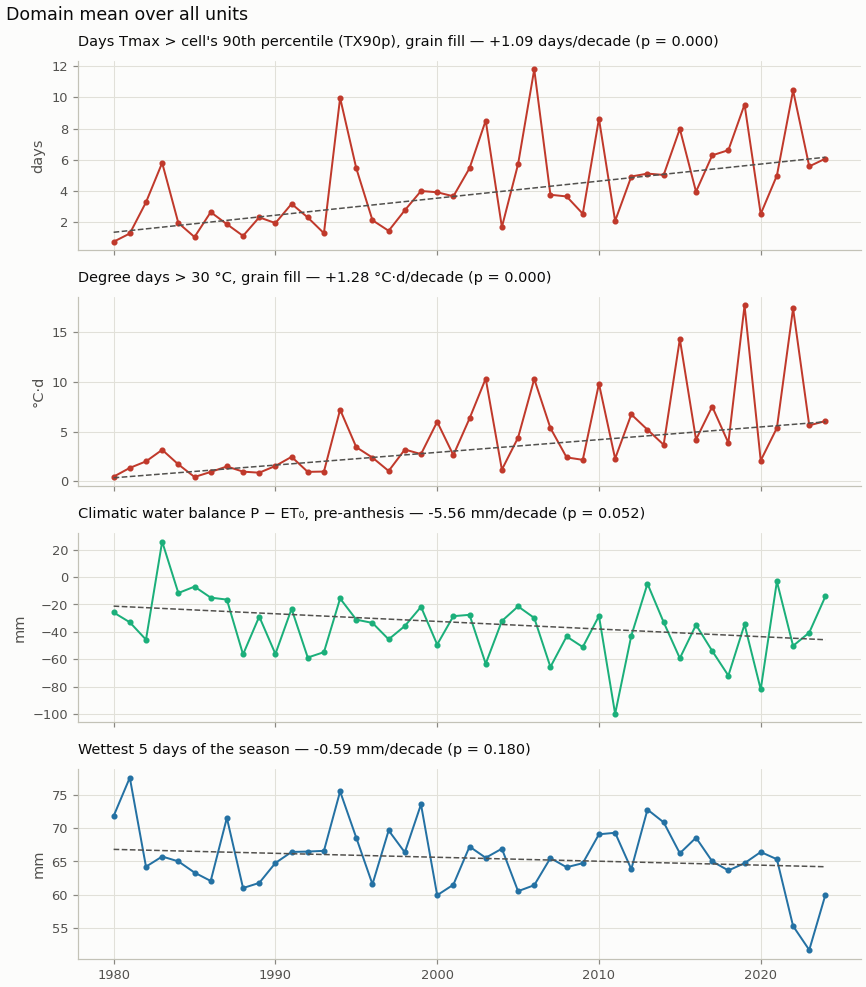

In [6]:
fig, axes = plt.subplots(len(HEADLINE), 1, figsize=(8.0, 2.3 * len(HEADLINE)), sharex=True)
domain = features.groupby("year")[HEADLINE].mean()
for ax, var in zip(axes, HEADLINE):
    group, unit, label = ex.FEATURES[var]
    series = domain[var]
    test = att.mk.original_test(series.to_numpy())
    ax.plot(series.index, series, color=GROUP_COLOURS[group], marker="o", ms=3, lw=1.3)
    ax.plot(series.index, test.intercept + test.slope * np.arange(len(series)),
            color=PALETTE["secondary"], lw=1, ls="--")
    ax.set_ylabel(unit)
    ax.set_title(f"{label} — {10 * test.slope:+.2f} {unit}/decade (p = {test.p:.3f})",
                 loc="left", fontsize=plt.rcParams["font.size"])
fig.suptitle("Domain mean over all units", x=0.01, ha="left")
fig.tight_layout()
save(fig, "hazard_trends_domain", FIGURES);

## 3. Yield anomalies and losses

The first row shows how often each series falls ≥ 10 % below its trend. The
second row is a check on the models before their attributions are taken
seriously: the per-unit correlation of each model's detrended anomaly with the
observed one, over the years both cover. Where this is near zero, the model's
attribution in §5 describes how the model responds, not what happened in that
unit.

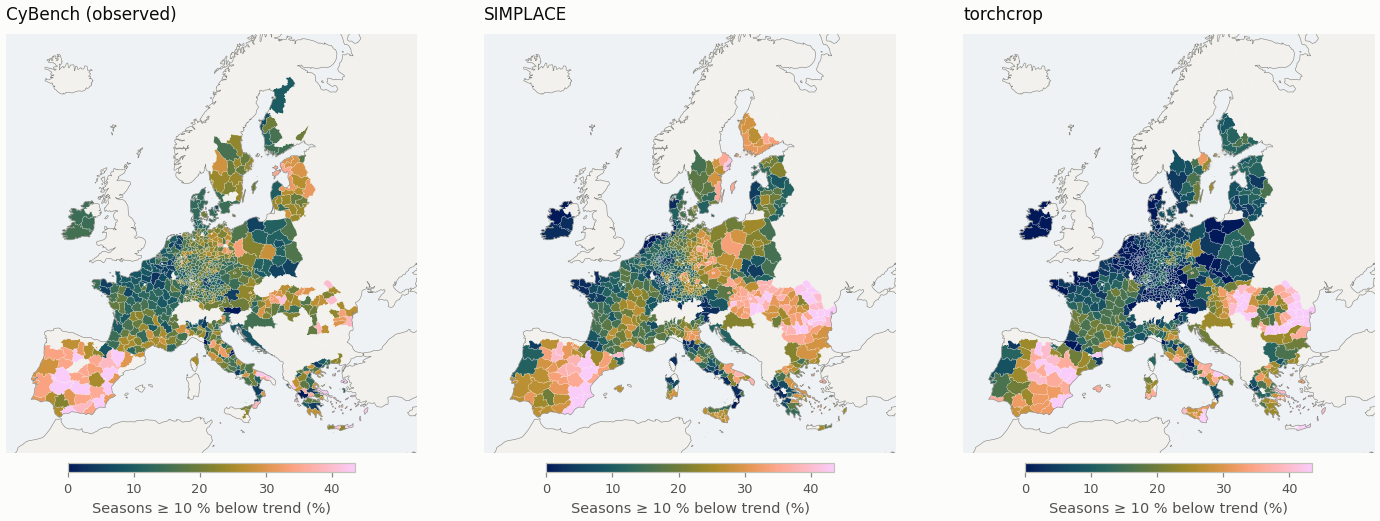

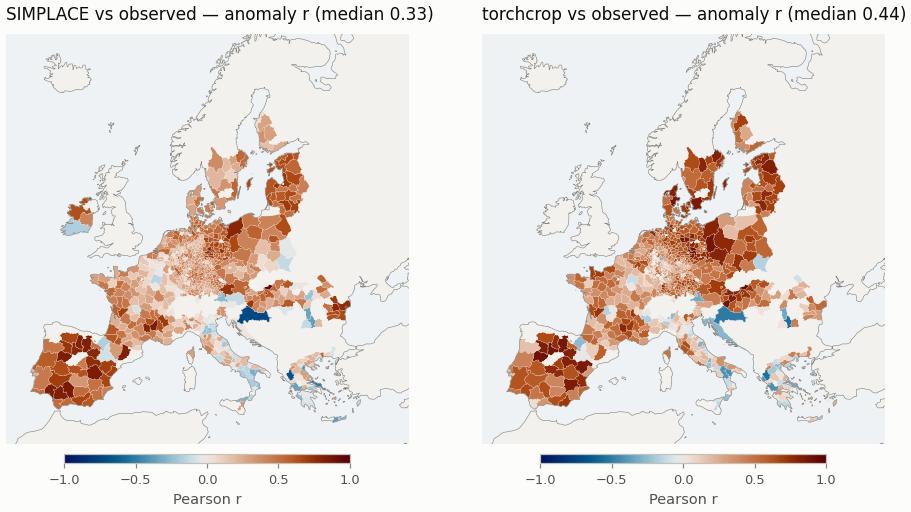

In [7]:
fig, axes = map_row(3)
freq = anomalies.groupby(["dataset", "adm_id"])["loss"].mean() * 100
vmax = _limit(freq, 0.97)
for ax, (ds, label) in zip(axes, att.DATASETS.items()):
    country_choropleth(polygons, freq.loc[ds], key_col="adm_id", diverging=False,
                       cmap=SEQUENTIAL_CMAP, vmin=0, vmax=vmax, linewidth=0.1,
                       title=label, cbar_label="Seasons ≥ 10 % below trend (%)", ax=ax)
fig.tight_layout()
save(fig, "loss_frequency", FIGURES)

wide = anomalies.pivot_table(index=["adm_id", "year"], columns="dataset", values="anomaly_pct")
skill = {m: wide[["observed", m]].dropna().groupby("adm_id")
         .apply(lambda g: g["observed"].corr(g[m]) if len(g) >= att.MIN_YEARS else np.nan)
         for m in ("simplace", "torchcrop")}
fig, axes = map_row(2)
for ax, (m, r) in zip(axes, skill.items()):
    country_choropleth(polygons, r, key_col="adm_id", diverging=True, vmax=1.0, linewidth=0.1,
                       title=f"{att.DATASETS[m]} vs observed — anomaly r (median {r.median():.2f})",
                       cbar_label="Pearson r", ax=ax)
fig.tight_layout()
save(fig, "anomaly_correlation", FIGURES);

SIMPLACE runs with fixed management and cultivar parameters, so its 1980–2024
yield trend is driven by **climate and CO₂ alone**, the counterpart of the hazard
trends in §2:

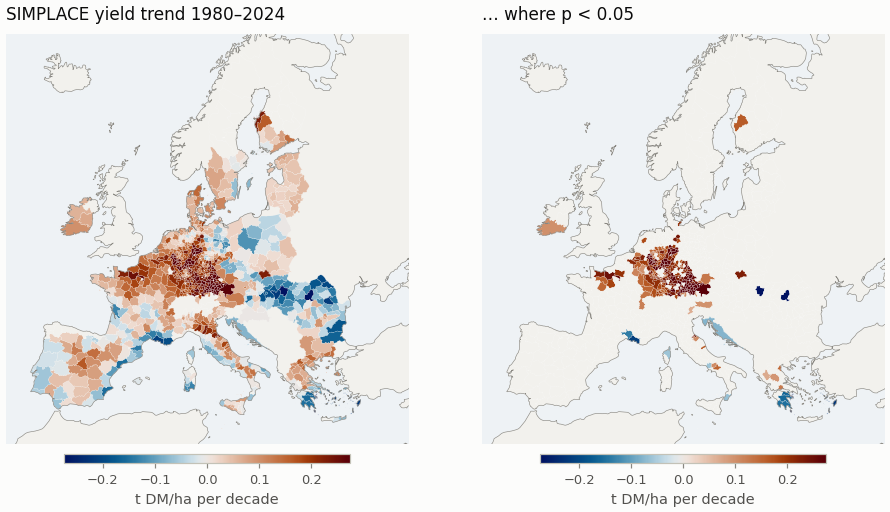

In [8]:
sim_yield = anomalies[anomalies["dataset"] == "simplace"]
yield_trend = att.sen_trends(sim_yield, ["yield_t_ha"]).set_index("adm_id")
yield_trend.to_csv(TABLES / "simplace_yield_trend.csv")
fig, axes = map_row(2)
country_choropleth(polygons, yield_trend["slope"], key_col="adm_id", diverging=True,
                   vmax=_limit(yield_trend["slope"]), linewidth=0.1,
                   title="SIMPLACE yield trend 1980–2024", cbar_label="t DM/ha per decade",
                   ax=axes[0])
country_choropleth(polygons, yield_trend["slope"].where(yield_trend["p"] < 0.05), key_col="adm_id",
                   diverging=True, vmax=_limit(yield_trend["slope"]), linewidth=0.1,
                   title="… where p < 0.05", cbar_label="t DM/ha per decade", ax=axes[1])
fig.tight_layout()
save(fig, "simplace_yield_trend", FIGURES);

## 4. Feature importance

One model per series, pooled over all units. The table gives held-out R² with
whole seasons left out. Importance is the R² lost when a hazard's indices are
permuted together on the held-out seasons. Because R² is pooled, a hazard that
explains a few large losses can rank above one that explains many small
anomalies.

In [9]:
hazards = att.hazard_anomalies(features)
designs = {ds: att.design(anomalies[anomalies["dataset"] == ds], hazards) for ds in att.DATASETS}
models = {ds: att.fit_driver_model(frame, ds) for ds, frame in designs.items()}
importance = pd.concat({ds: m.importance.iloc[0] for ds, m in models.items()}, axis=1).T
importance.insert(0, "R² (held-out years)", [m.r2 for m in models.values()])
importance.to_csv(TABLES / "grouped_importance.csv")
importance.rename(columns=att.GROUP_LABELS).round(3)

,R² (held-out years),Heat,Drought,Heavy precipitation,Other weather,n
observed,0.049,0.002,0.089,0.003,0.057,23016.0
simplace,0.274,0.021,0.439,0.057,0.018,38202.0
torchcrop,0.376,0.168,0.502,0.015,0.041,21217.0


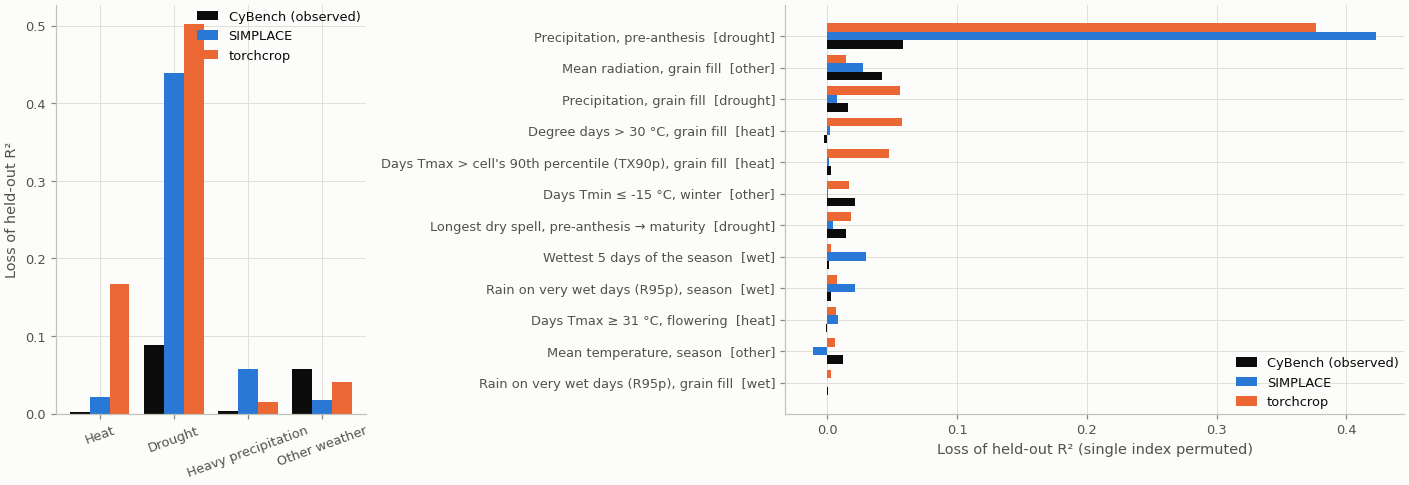

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6), gridspec_kw={"width_ratios": [1, 2]})
width = 0.8 / len(models)
for i, ds in enumerate(models):
    vals = importance.loc[ds, list(ex.GROUPS)]
    axes[0].bar(np.arange(len(vals)) + i * width, vals, width, color=COLOURS[ds],
                label=att.DATASETS[ds])
axes[0].set_xticks(np.arange(len(ex.GROUPS)) + width, [att.GROUP_LABELS[g] for g in ex.GROUPS],
                   rotation=20)
axes[0].set_ylabel("Loss of held-out R²")
axes[0].legend(frameon=False)

per_feature = pd.concat({ds: att.per_feature_importance(designs[ds]) for ds in models}, axis=1)
per_feature.to_csv(TABLES / "feature_importance.csv")
order = per_feature.mean(axis=1).sort_values().index
y = np.arange(len(order))
for i, ds in enumerate(models):
    axes[1].barh(y + i * width, per_feature.loc[order, ds], width, color=COLOURS[ds],
                 label=att.DATASETS[ds])
axes[1].set_yticks(y + width, [f"{ex.FEATURES[f][2]}  [{ex.FEATURES[f][0]}]" for f in order])
axes[1].legend(frameon=False)
axes[1].set_xlabel("Loss of held-out R² (single index permuted)")
fig.tight_layout()
save(fig, "feature_importance", FIGURES);

### Importance by country

Each model's held-out rows are re-pooled by country. This shows where a hazard
matters, without fitting a separate model per country with only a few hundred
seasons each. Countries with fewer than 150 seasons are omitted.

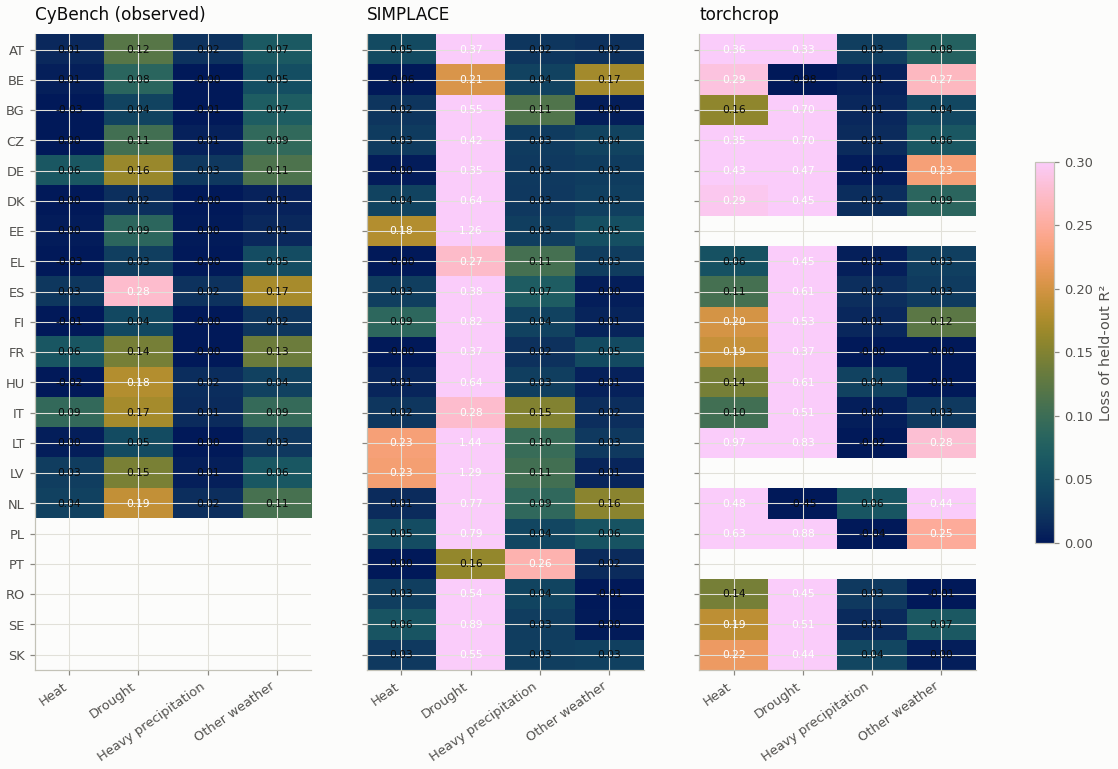

In [11]:
fig, axes = plt.subplots(1, len(models), figsize=(4.6 * len(models), 7.5), sharey=True)
by_country = {}
for ax, (ds, m) in zip(axes, models.items()):
    rows = m.rows.assign(country=m.rows["adm_id"].map(unit_country))
    imp = att.grouped_importance(rows, by="country")
    imp = imp[imp["n"] >= 150][list(ex.GROUPS)]
    by_country[ds] = imp
    imp = imp.reindex(sorted(set().union(*[v.index for v in by_country.values()])))
    im = ax.imshow(imp.to_numpy(), cmap=SEQUENTIAL_CMAP, vmin=0, vmax=0.3, aspect="auto")
    ax.set_xticks(range(len(ex.GROUPS)), [att.GROUP_LABELS[g] for g in ex.GROUPS], rotation=35,
                  ha="right")
    ax.set_yticks(range(len(imp)), imp.index)
    ax.set_title(att.DATASETS[ds])
    for (r, c), v in np.ndenumerate(imp.to_numpy()):
        if np.isfinite(v):
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.18 else PALETTE["primary"])
fig.colorbar(im, ax=axes, shrink=0.6, label="Loss of held-out R²")
pd.concat(by_country).to_csv(TABLES / "grouped_importance_by_country.csv")
save(fig, "importance_by_country", FIGURES);

## 5. Regions with heat- or drought-driven losses

For each unit, the mean contribution of each hazard over its **loss seasons**
(% of trend yield). The driver is the most negative of these. Heat and drought
are labelled **compound** when the weaker contribution is at least 60 % of the
stronger. A unit is **no clear signal** when no group's contribution reaches
−2 %. Units with fewer than two loss seasons are left blank.

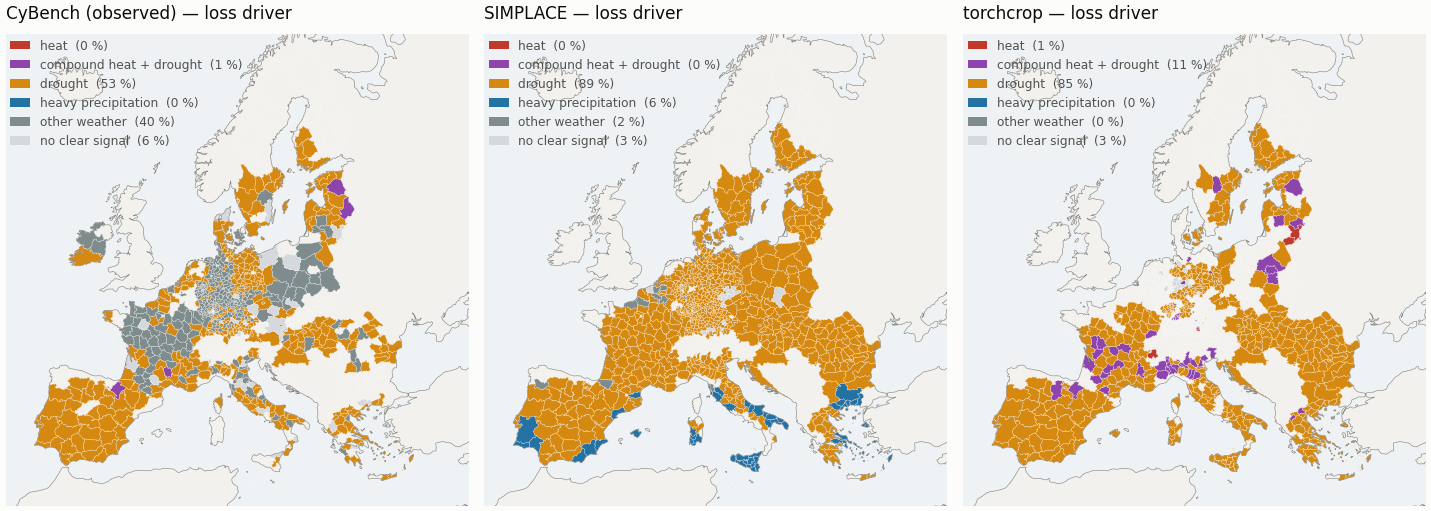

In [12]:
drivers = {ds: att.classify_drivers(m.contributions) for ds, m in models.items()}
pd.concat(drivers, names=["dataset"]).to_csv(TABLES / "unit_loss_drivers.csv")
fig, axes = map_row(3, height=5.6)
for ax, (ds, d) in zip(axes, drivers.items()):
    att.category_choropleth(polygons, d.set_index("adm_id")["driver"], ax=ax,
                            title=f"{att.DATASETS[ds]} — loss driver")
fig.tight_layout()
save(fig, "loss_drivers", FIGURES);

The continuous values behind the labels: mean heat and drought contributions in
the loss seasons. Blue means the hazard pulled yield below trend.

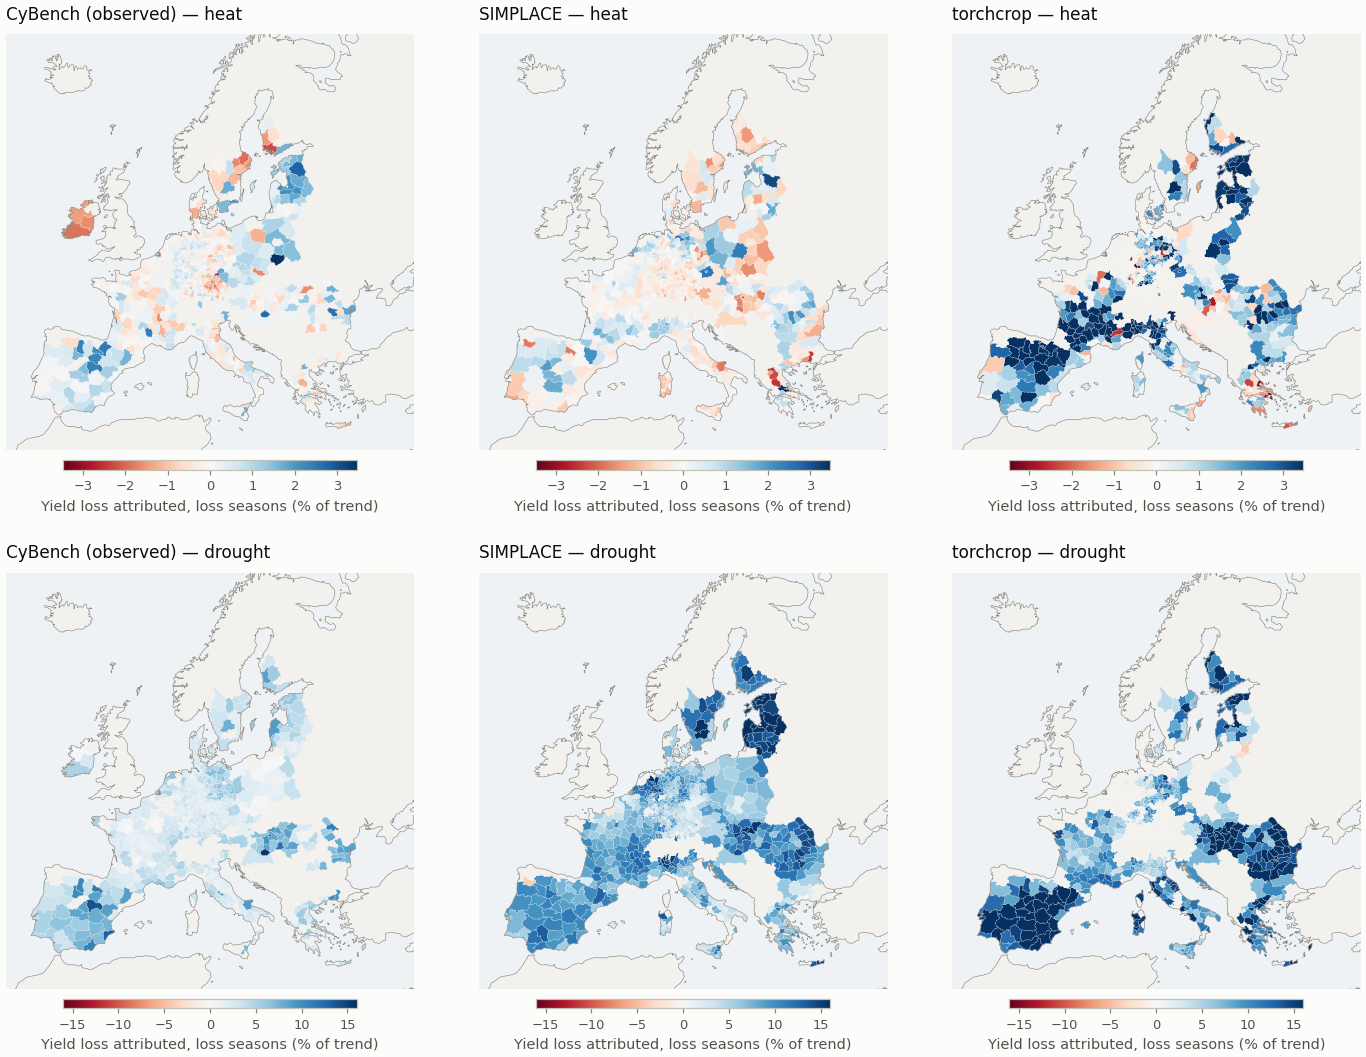

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13.2, 10.0), subplot_kw={"projection": EUROPE_PROJECTION})
for r, group in enumerate(("heat", "drought")):
    vmax = _limit(pd.concat([d[group] for d in drivers.values()]))
    for c, (ds, d) in enumerate(drivers.items()):
        country_choropleth(polygons, -d.set_index("adm_id")[group], key_col="adm_id",
                           diverging=True, vmax=vmax, linewidth=0.1,
                           cmap=plt.get_cmap("RdBu"),
                           title=f"{att.DATASETS[ds]} — {att.GROUP_LABELS[group].lower()}",
                           cbar_label="Yield loss attributed, loss seasons (% of trend)",
                           ax=axes[r, c])
fig.tight_layout()
save(fig, "heat_drought_contributions", FIGURES);

The share of units per driver, by country (observed series):

In [14]:
obs = drivers["observed"].assign(country=drivers["observed"]["adm_id"].map(unit_country))
share = pd.crosstab(obs["country"], obs["driver"], normalize="index").mul(100).round(0)
share = share[[c for c in att.DRIVERS if c in share]]
share.insert(0, "units", obs.groupby("country").size())
share.to_csv(TABLES / "observed_driver_share_by_country.csv")
share

driver,units,compound heat + drought,drought,other weather,no clear signal
country,,,,,
AT,6,0.0,67.0,0.0,33.0
BE,5,0.0,40.0,60.0,0.0
CZ,14,0.0,36.0,43.0,21.0
DE,361,0.0,43.0,54.0,4.0
DK,8,0.0,62.0,25.0,12.0
EE,5,20.0,80.0,0.0,0.0
EL,34,0.0,79.0,6.0,15.0
ES,33,3.0,97.0,0.0,0.0
FI,5,0.0,100.0,0.0,0.0


How often the models name the same driver as the observations, over units
labelled in both:

In [15]:
labels = pd.concat({ds: d.set_index("adm_id")["driver"] for ds, d in drivers.items()}, axis=1)
pd.DataFrame({m: {
    "units labelled in both": int(labels[["observed", m]].dropna().shape[0]),
    "same driver (%)": round(100 * (labels["observed"] == labels[m])[labels[["observed", m]].notna().all(axis=1)].mean(), 1),
} for m in ("simplace", "torchcrop")}).T

,units labelled in both,same driver (%)
simplace,695.0,47.8
torchcrop,426.0,54.5


### Model-free cross-check

Spearman correlation between the observed anomaly and two indices: grain-fill
TX90p, and pre-anthesis precipitation. This uses no fitted model. A
heat-driven unit should be negative on the left (more hot days, less yield). A
drought-driven unit should be positive on the right (wetter, more yield).

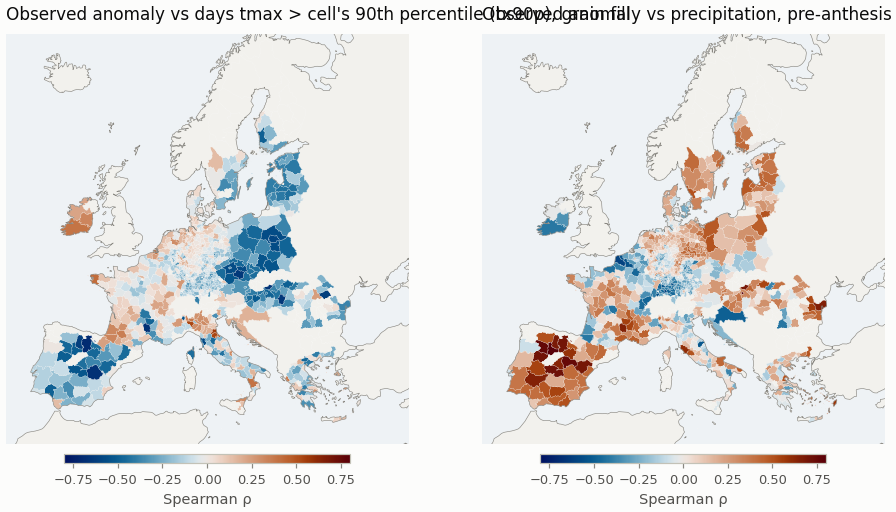

In [16]:
obs_frame = designs["observed"]
rho = {v: obs_frame.groupby("adm_id")[["anomaly_pct", v]].apply(
           lambda g: g["anomaly_pct"].corr(g[v], method="spearman") if len(g) >= att.MIN_YEARS else np.nan)
       for v in ("tx90p_grainfill", "prec_preanthesis")}
fig, axes = map_row(2)
for ax, (v, r) in zip(axes, rho.items()):
    country_choropleth(polygons, r, key_col="adm_id", diverging=True, vmax=0.8, linewidth=0.1,
                       title=f"Observed anomaly vs {ex.FEATURES[v][2].lower()}",
                       cbar_label="Spearman ρ", ax=ax)
fig.tight_layout()
save(fig, "observed_spearman", FIGURES);

## 6. Are hazard-driven losses growing?

The domain-mean contribution of each hazard per season, with a Theil–Sen
trend. SIMPLACE's 45 seasons are the only series long enough for the trend to
mean much; the observed and torchcrop series cover 22–25 seasons.

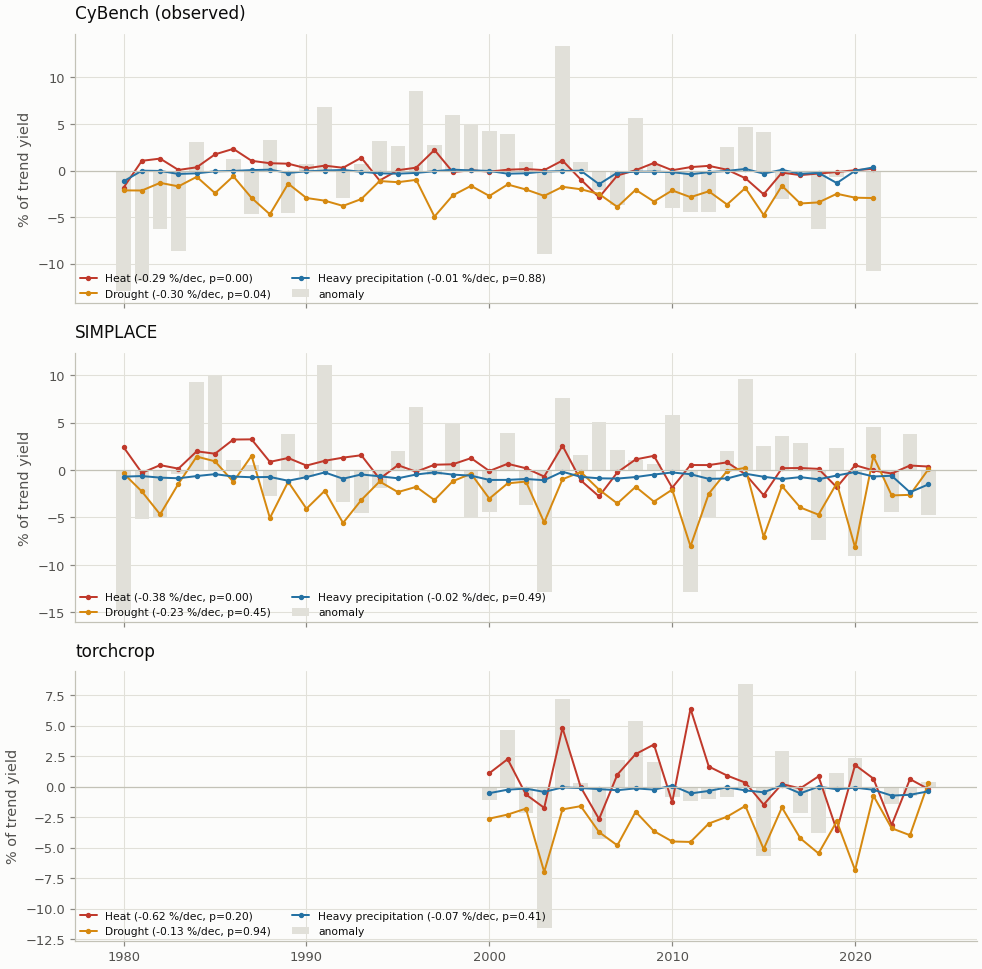

In [17]:
fig, axes = plt.subplots(len(models), 1, figsize=(9.0, 3.0 * len(models)), sharex=True)
rows = []
for ax, (ds, m) in zip(axes, models.items()):
    yearly = att.yearly_contributions(m.contributions)
    ax.bar(yearly.index, yearly["anomaly_pct"], color=PALETTE["grid"], label="anomaly")
    for g in ("heat", "drought", "wet"):
        test = att.mk.original_test(yearly[g].to_numpy())
        rows.append({"dataset": ds, "group": g, "slope_pct_per_decade": 10 * test.slope, "p": test.p})
        ax.plot(yearly.index, yearly[g], color=GROUP_COLOURS[g], marker="o", ms=2.5, lw=1.3,
                label=f"{att.GROUP_LABELS[g]} ({10 * test.slope:+.2f} %/dec, p={test.p:.2f})")
    ax.axhline(0, color=PALETTE["baseline"], lw=0.8)
    ax.set_ylabel("% of trend yield")
    ax.set_title(att.DATASETS[ds], loc="left")
    ax.legend(frameon=False, fontsize=7, ncols=2, loc="lower left")
fig.tight_layout()
pd.DataFrame(rows).to_csv(TABLES / "contribution_trends.csv", index=False)
save(fig, "contribution_timeseries", FIGURES);

Per-unit SIMPLACE trend (1980–2024) in the heat and drought contributions. Blue
means that hazard's yield penalty is getting larger:

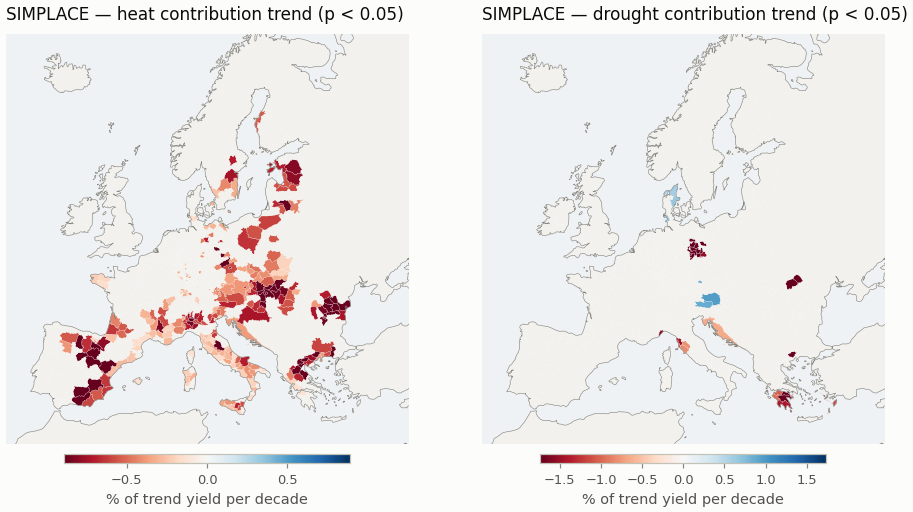

In [18]:
contrib_trend = att.sen_trends(models["simplace"].contributions, ["heat", "drought"])
fig, axes = map_row(2)
for ax, g in zip(axes, ("heat", "drought")):
    t = contrib_trend[contrib_trend["variable"] == g].set_index("adm_id")
    country_choropleth(polygons, t["slope"].where(t["p"] < 0.05), key_col="adm_id", diverging=True,
                       vmax=_limit(t["slope"]), cmap=plt.get_cmap("RdBu"), linewidth=0.1,
                       title=f"SIMPLACE — {att.GROUP_LABELS[g].lower()} contribution trend (p < 0.05)",
                       cbar_label="% of trend yield per decade", ax=ax)
fig.tight_layout()
save(fig, "simplace_contribution_trends", FIGURES);

## 7. Sensitivity of the attribution

The attribution is rerun in two variants, and each is compared with the main run:

* **Common years and units**: only unit-years that all three series have, in
  2000–2021, with yields re-detrended on that window. Differences between
  observed and model attribution can then no longer come from different
  samples.
* **Detrended hazards**: each index measured against the unit's own
  1980–2024 linear trend rather than its mean. Shocks are then compared with
  shocks, matching the detrended yields. Any slow hazard-driven decline is
  absorbed by both trends. If a driver label survives this variant, it is
  set by year-to-year shocks rather than by the trends in the hazards.

In [19]:
variants = {
    "common years & units": (att.common_sample(anomalies), hazards),
    "detrended hazards": (anomalies, att.hazard_anomalies(features, detrended=True)),
}
variant_models = {"main": models} | {
    name: {ds: att.fit_driver_model(att.design(a[a["dataset"] == ds], h), ds, n_repeats=2)
           for ds in att.DATASETS}
    for name, (a, h) in variants.items()
}
variant_drivers = {name: {ds: att.classify_drivers(m.contributions) for ds, m in ms.items()}
                   for name, ms in variant_models.items()}

summary = pd.DataFrame([
    {"variant": name, "dataset": ds, "seasons": len(m.rows), "R²": m.r2,
     **{att.GROUP_LABELS[g]: m.importance.iloc[0][g] for g in ex.GROUPS},
     "same driver as main (%)": att.label_agreement(variant_drivers[name][ds],
                                                    variant_drivers["main"][ds])}
    for name, ms in variant_models.items() for ds, m in ms.items()
]).set_index(["variant", "dataset"])
summary.to_csv(TABLES / "sensitivity_summary.csv")
summary.round(3)

seasons     R²   Heat  Drought  \
variant              dataset                                     
main                 observed     23016  0.049  0.002    0.089   
                     simplace     38202  0.274  0.021    0.439   
                     torchcrop    21217  0.376  0.168    0.502   
common years & units observed     14552  0.059  0.022    0.071   
                     simplace     14552  0.230  0.010    0.459   
                     torchcrop    14552  0.324  0.143    0.491   
detrended hazards    observed     23016  0.076  0.028    0.081   
                     simplace     38202  0.288  0.034    0.450   
                     torchcrop    21217  0.356  0.129    0.476   

                                Heavy precipitation  Other weather  \
variant              dataset                                         
main                 observed                 0.003          0.057   
                     simplace                 0.057          0.018   
                     torchcrop                0.015          0.041   
common years & units observed                -0.002          0.064   
                     simplace                 0.025          0.025   
                     torchcrop                0.009          0.049   
detrended hazards    observed                 0.006          0.078   
                     simplace                 0.058          0.019   
                     torchcrop                0.020          0.026   

                                same driver as main (%)  
variant              dataset                             
main                 observed                   100.000  
                     simplace                   100.000  
                     torchcrop                  100.000  
common years & units observed                    49.614  
                     simplace                    90.579  
                     torchcrop                   84.533  
detrended hazards    observed                    66.667  
                     simplace                    95.280  
                     torchcrop                   89.453

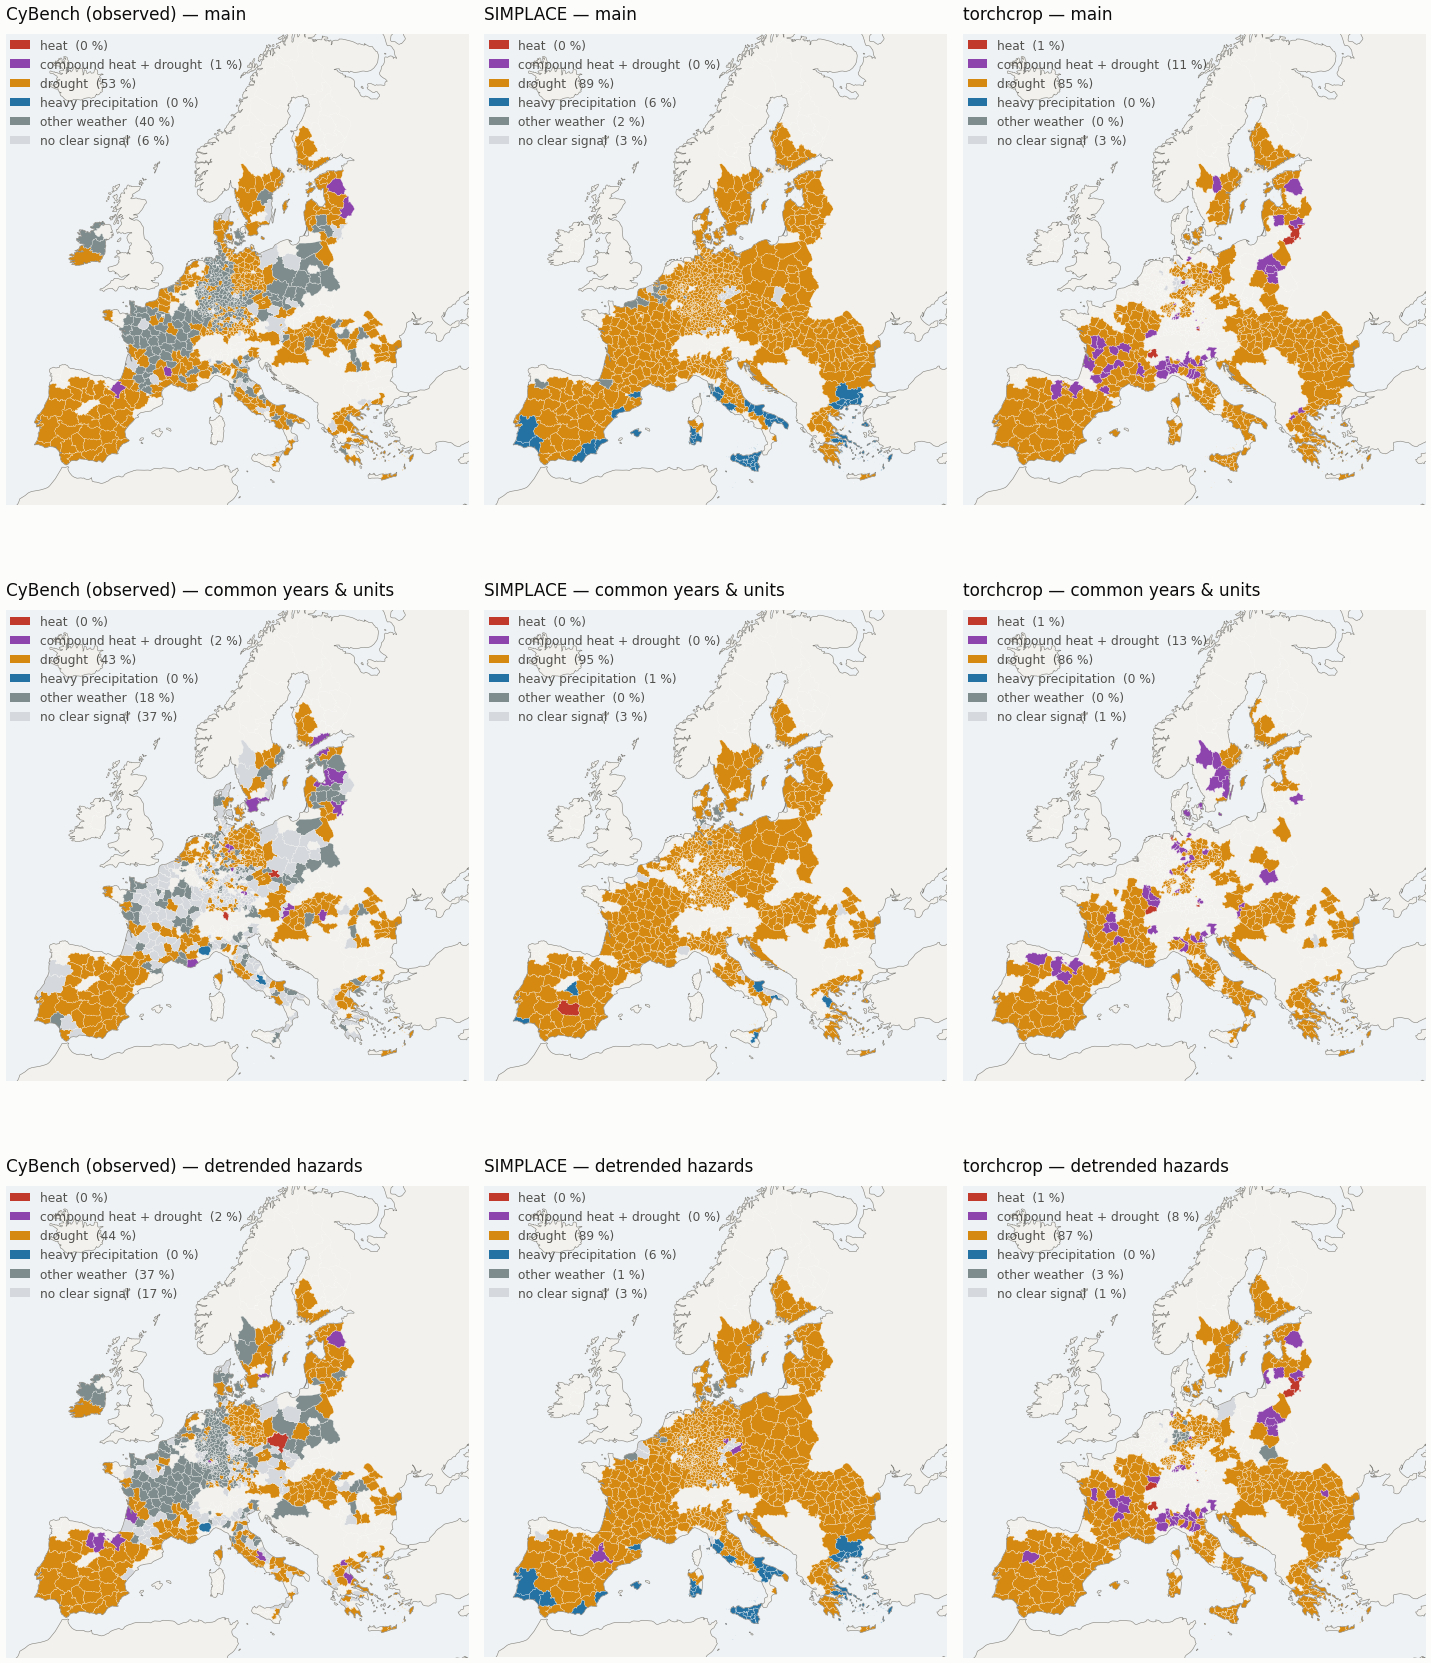

In [20]:
fig, axes = plt.subplots(len(variant_drivers), len(att.DATASETS),
                         figsize=(13.2, 5.4 * len(variant_drivers)),
                         subplot_kw={"projection": EUROPE_PROJECTION})
for r, (name, by_ds) in enumerate(variant_drivers.items()):
    for c, (ds, d) in enumerate(by_ds.items()):
        att.category_choropleth(polygons, d.set_index("adm_id")["driver"], ax=axes[r, c],
                                title=f"{att.DATASETS[ds]} — {name}")
fig.tight_layout()
save(fig, "loss_drivers_sensitivity", FIGURES);

The share of units per driver in each variant, and how often each model names
the observed driver. The common-sample row is the like-for-like comparison:

In [21]:
shares = pd.concat({
    (name, ds): d["driver"].value_counts(normalize=True).mul(100)
    for name, by_ds in variant_drivers.items() for ds, d in by_ds.items()
}).unstack().reindex(columns=list(att.DRIVERS)).fillna(0).round(0)
agreement = pd.DataFrame({
    name: {m: att.label_agreement(by_ds["observed"], by_ds[m]) for m in ("simplace", "torchcrop")}
    for name, by_ds in variant_drivers.items()
}).T.round(1).add_suffix(" = observed (%)")
display(shares)
agreement

driver                          heat  compound heat + drought  drought  \
common years & units observed    0.0                      2.0     43.0   
                     simplace    0.0                      0.0     95.0   
                     torchcrop   1.0                     13.0     86.0   
detrended hazards    observed    0.0                      2.0     44.0   
                     simplace    0.0                      0.0     89.0   
                     torchcrop   1.0                      8.0     87.0   
main                 observed    0.0                      1.0     53.0   
                     simplace    0.0                      0.0     89.0   
                     torchcrop   1.0                     11.0     85.0   

driver                          heavy precipitation  other weather  \
common years & units observed                   0.0           18.0   
                     simplace                   1.0            0.0   
                     torchcrop                  0.0            0.0   
detrended hazards    observed                   0.0           37.0   
                     simplace                   6.0            1.0   
                     torchcrop                  0.0            3.0   
main                 observed                   0.0           40.0   
                     simplace                   6.0            2.0   
                     torchcrop                  0.0            0.0   

driver                          no clear signal  
common years & units observed              37.0  
                     simplace               3.0  
                     torchcrop              1.0  
detrended hazards    observed              17.0  
                     simplace               3.0  
                     torchcrop              1.0  
main                 observed               6.0  
                     simplace               3.0  
                     torchcrop              3.0

,simplace = observed (%),torchcrop = observed (%)
main,47.8,54.5
common years & units,43.4,49.1
detrended hazards,40.9,55.2


## 8. Caveats

* **Fixed windows.** Hazards are read in climatological phenology windows. In a
  hot year the real crop flowers earlier, so heat late in a fixed grain-fill
  window may fall after maturity. Heat exposure is therefore an upper bound in
  hot seasons.
* **Correlated hazards.** Hot springs are dry springs. Grouped permutation keeps
  each group's own indices together, but heat and drought still share
  variance. The *compound* class exists so that this overlap is not reported
  as a winner.
* **Observed losses include non-weather causes**: pests, policy and statistical
  breaks in CyBench. These lower the observed R² but should not bias the hazard
  ranking.
* **Model attribution describes the model.** Where §3's anomaly correlation is
  low, a model's driver map shows what limits its yield in that unit, not what
  limited the real crop.
* **Heavy precipitation** affects the models only through soil water: neither
  simulates lodging, harvest losses or disease. Their wet-driven losses are
  therefore a lower bound, and the observed series is the one to read for that
  hazard.